# Lab03 — 02. Modeling: baseline → train → evaluate → visualize

Notebook duy nhất cho modeling, gồm cả Exercise 1 pretrained sentiment và Exercise 2 binary fine-tuning. **MODE="view"** mặc định đã lưu output từ artifact Kaggle; đổi **MODE="train"** để train mới trên Kaggle/local. **DEVICE="auto"** chọn CUDA nếu có, nếu không CPU; có thể chọn rõ cuda/cpu. CPU đầy đủ được hỗ trợ nhưng chậm, khuyến nghị CUDA. Không nạp checkpoint cũ để resume: train từ pretrained base.

| Phase | Nội dung | Module/file | Artifact |
|---|---|---|---|
| 1 | Setup và preflight | src/notebook_runtime.py, tests/ | outputs/preflight |
| 2 | Exercise 1 pretrained sentiment | src/models/classifier.py | pipeline/manual PNG |
| 3 | Kiến trúc/optimizer | config/frozen_trial.json, training/frozen.py | config và nhóm tham số |
| 4 | Baseline + train đủ 10 epoch | scripts/run_frozen_trial.py, trainer.py | epoch_history, learning_curves |
| 5 | Validation checkpoint + threshold | training/thresholds.py | policy, threshold curves |
| 6 | Test và confidence | training/metrics.py | confusion, ROC/PR/calibration |
| 7 | Lỗi và so sánh | src/final_review.py | sample/comparison PNG |
| 8 | Artifact và ZIP | src/utils/runs.py | manifest, review/checkpoint ZIP |

Dữ liệu, preprocessing và feature engineering được giải thích trong [notebook 01](01_eda_preprocessing_feature_engineering.ipynb). Cấu hình giữ nguyên lượt frozen đã đo: embedding + 4 tầng đầu đóng băng, LR encoder/head 2e-6/1e-5, dropout 0.2/0.2/0.4, decay 0.1, 10 epoch. Thay bố cục không thay kết quả lịch sử.


## 1. Setup và preflight

Đổi MODE="train" ở cell đầu để thực thi. MODE=view chỉ đọc kết quả đã lưu. Preflight dùng fixture CPU nhỏ trước full training; không dùng model sanity làm model train chính.

In [1]:
from pathlib import Path
import subprocess, sys
MODE = "view"  # Notebook 01: view/prepare. Notebook 02: view/train.
DEVICE = "auto"  # auto/cuda/cpu; local CPU được hỗ trợ nhưng chậm.
start = Path.cwd().resolve()
REPO = next((p for p in (start,*start.parents) if (p/"labs/lab03/config/report.json").is_file()), None)
if REPO is None and Path("/kaggle/working").is_dir():
    REPO = Path("/kaggle/working/Lab-DL")
    if not REPO.exists():
        subprocess.run(["git","clone","--branch","lab03","--single-branch","https://github.com/lacthui06/Lab-DL.git",str(REPO)],check=True)
assert REPO is not None, "Mở notebook từ repo đã clone."
sys.path.insert(0,str(REPO))
from labs.lab03.src.notebook_runtime import NotebookSession
session = NotebookSession(REPO, MODE, DEVICE)
session.setup()
from IPython.display import display


Python: 3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
PyTorch: 2.6.0+cpu
CUDA available: False


Mode: view Device request: auto Artifacts: /workspace/Lab-DL-completion/labs/lab03/outputs


In [2]:
session.preflight()


View mode: dùng bằng chứng đã lưu; không chạy lại tests hoặc training.


## 2. Exercise 1 — Pretrained sentiment

Mô hình SST-2 dùng cho inference, khác DistilBERT base của Exercise 2. Pipeline và manual forward phải nhất quán. Confidence cao không bảo đảm từng dự đoán đúng.

,text,label,score,probabilities
0,I love this wonderful movie!,POSITIVE,0.999878,"[0.0001224386360263452, 0.9998775720596313]"
1,This movie was terrible and boring.,NEGATIVE,0.999768,"[0.9997683167457581, 0.00023167315521277487]"
2,"The acting was good, but the story was disappo...",NEGATIVE,0.996749,"[0.9967492818832397, 0.0032507420983165503]"


**sentiment_predictions.png**

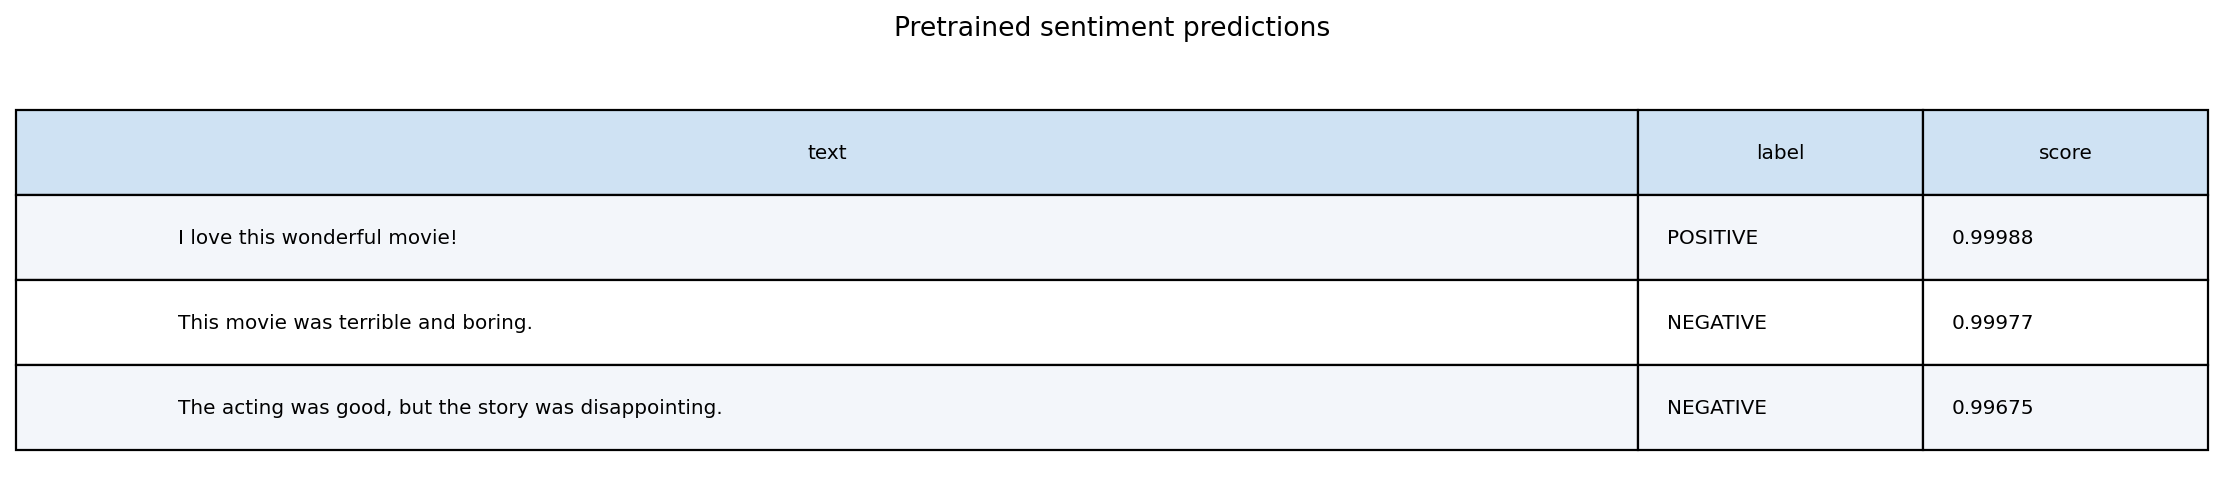

**pipeline_manual_comparison.png**

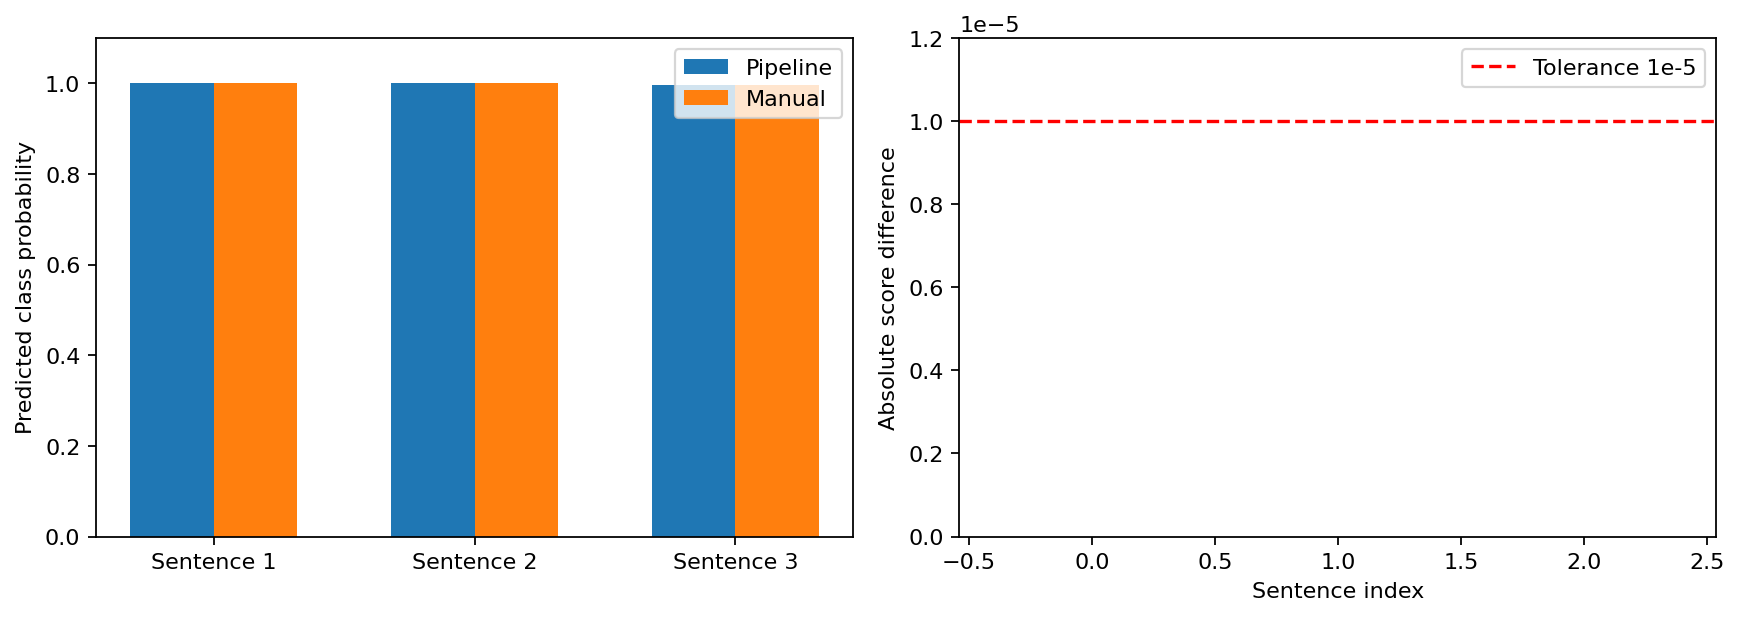

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095630Z_exercise1_analysis_dc3ef4d7/sentiment_predictions.png'),
 PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095630Z_exercise1_analysis_dc3ef4d7/pipeline_manual_comparison.png')]

In [3]:
session.exercise1()
display(session.table("exercise1_current", "predictions.json", "manual"))
session.show("exercise1_visuals", ["sentiment_predictions.png", "pipeline_manual_comparison.png"])


## 3. Cấu hình modeling

Baseline TF-IDF + logistic regression và Transformer dùng cùng augmented train pool. Embedding và bốn tầng đầu không được optimizer cập nhật. Bias/LayerNorm không decay. Classification head mới có LR lớn hơn encoder để học bài toán đích.

In [4]:
config = session.read(session.lab/"config/frozen_trial.json")
display(config["exercise2"])


{'dataset_name': 'cornell-movie-review-data/rotten_tomatoes',
 'dataset_revision': 'aa13bc287fa6fcab6daf52f0dfb9994269ffea28',
 'model_name': 'distilbert/distilbert-base-uncased',
 'model_revision': '12040accade4e8a0f71eabdb258fecc2e7e948be',
 'max_length': 128,
 'batch_size': 16,
 'eval_batch_size': 32,
 'learning_rate': 2e-06,
 'num_train_epochs': 10,
 'weight_decay': 0.1,
 'warmup_ratio': 0.1,
 'fp16': True,
 'threshold_selection': {'enabled': True,
  'selection_metric': 'macro_f1',
  'split': 'validation',
  'grid': '0.05 to 0.95, step 0.05',
  'tie_break': 'closest to 0.5, then smaller threshold'},
 'eval_strategy': 'epoch',
 'eval_steps': 100,
 'logging_steps': 25,
 'metric_for_best_model': 'loss',
 'gradient_accumulation_steps': 1,
 'max_grad_norm': 1.0,
 'dataloader_num_workers': 0,
 'save_only_model': True,
 'epoch_console_summary': True,
 'model_overrides': {'dropout': 0.2,
  'attention_dropout': 0.2,
  'seq_classif_dropout': 0.4},
 'augmentation': {'enabled': True, 'max_rati

## 4. Train hoặc xem đủ 10 epoch

MODE=train chạy baseline, full training, reload checkpoint tốt nhất, validation threshold rồi test trong đúng thứ tự; các cell sau chỉ trình bày artifact. Không chạy lại cell này chỉ để xem ảnh. Train/validation được đo trong eval mode: dropout tắt khi đo. Global steps có thể khác số cập nhật thành công do AMP skip.

View mode: không train; hiển thị frozen trial đã kiểm chứng.


,epoch,step,train_loss_eval,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate,epoch_runtime_seconds
0,1,551,0.612102,0.767151,0.612096,0.775797,0.775012,2.000000e-06,18.811370
1,2,1102,0.399959,0.818719,0.401842,0.819887,0.819872,1.778181e-06,18.313120
2,3,1653,0.384900,0.827351,0.387137,0.824578,0.824570,1.555959e-06,18.725699
3,4,2204,0.374508,0.833939,0.381047,0.833959,0.833799,1.334140e-06,18.806669
4,5,2755,0.369851,0.833598,0.376652,0.833959,0.833906,1.111918e-06,19.051578
5,6,3306,0.363106,0.839505,0.373288,0.834897,0.834783,8.896955e-07,18.647766
6,7,3857,0.362880,0.838483,0.371724,0.835835,0.835828,6.674733e-07,18.480643
7,8,4408,0.361536,0.839618,0.371199,0.837711,0.837710,4.456544e-07,18.620578
8,9,4959,0.357609,0.842117,0.369328,0.835835,0.835783,2.234321e-07,18.811372
9,10,5510,0.358071,0.842458,0.369622,0.837711,0.837679,1.209921e-09,19.155446


**learning_curves.png**

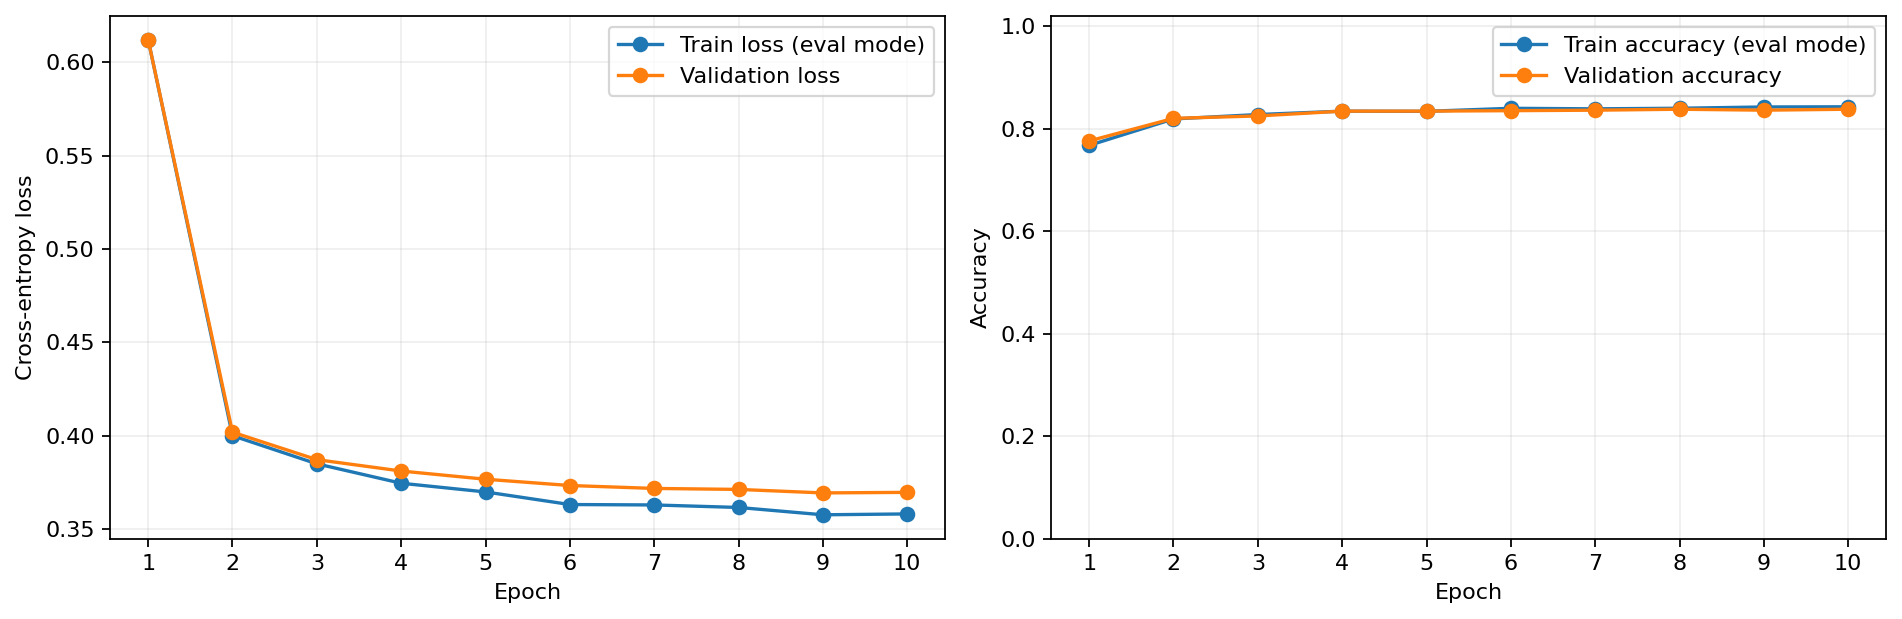

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095655Z_frozen_trial_d8d09116/learning_curves.png')]

In [5]:
session.train()
display(session.table("model", "epoch_history.json"))
session.show("model", ["learning_curves.png"])


### Đọc đường học

Artifact lưu sẵn: cuối epoch 10 train/validation accuracy 84.25%/83.77%, loss 0.3581/0.3696. Gap nhỏ hơn full fine-tuning nhưng không chứng minh mô hình tối ưu. Với MODE=train, đọc số mới trong bảng/ảnh thay vì gán số lịch sử cho run mới.

## 5. Validation checkpoint và threshold

Chọn checkpoint theo minimum validation loss, không mặc định epoch 10. Sau đó quét 19 validation thresholds để tối đa Macro-F1. Lượt lưu sẵn chọn epoch 9 và threshold 0.45; không chọn lại bằng test.

,completed_epochs,early_stopping,checkpoint_selection_metric,selected_epoch,best_step,best_validation_loss,global_step,amp_skipped_optimizer_steps,test_used_for_selection
0,10.0,False,validation_loss,9,4959,0.369328,5510,3,False


{'threshold': 0.45,
 'accuracy': 0.8405253283302064,
 'precision': 0.8367346938775511,
 'recall': 0.8461538461538461,
 'specificity': 0.8348968105065666,
 'FPR': 0.1651031894934334,
 'binary_f1': 0.8414179104477612,
 'macro_f1': 0.8405202759785976,
 'TN': 445,
 'FP': 88,
 'FN': 82,
 'TP': 451,
 'negative_support': 533,
 'positive_support': 533,
 'sample_count': 1066}

**validation_threshold_curves.png**

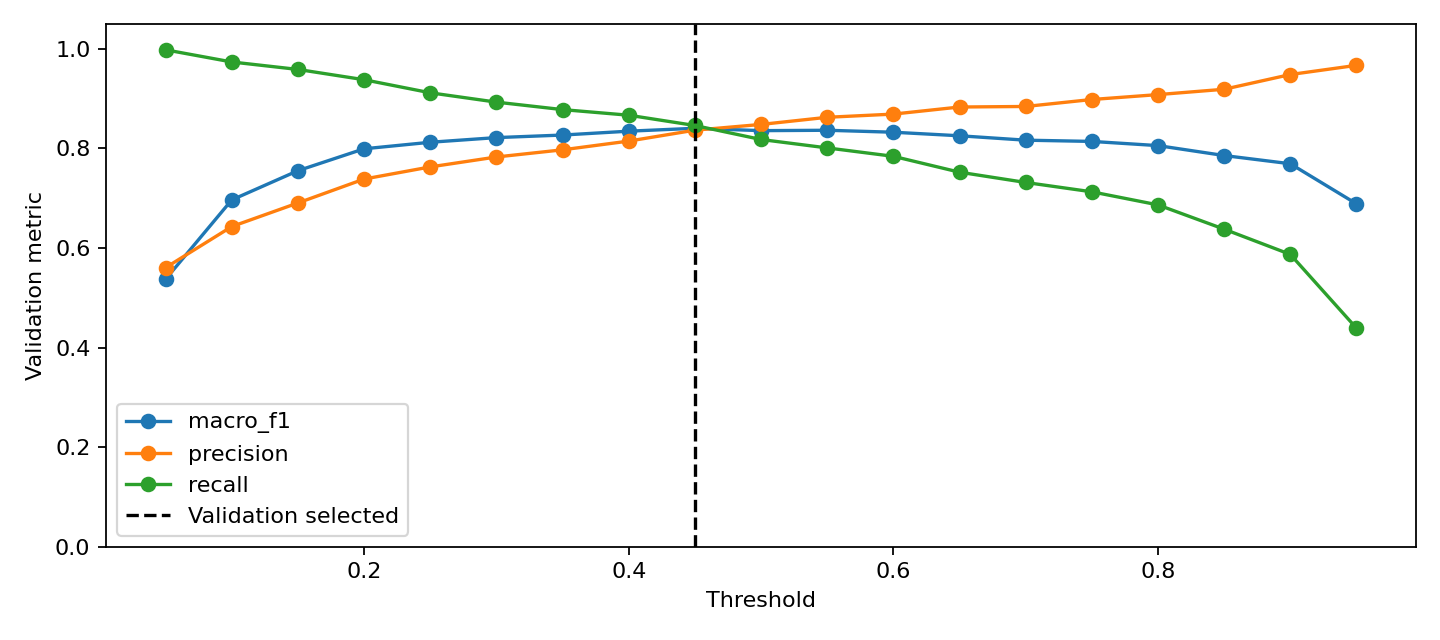

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095655Z_frozen_trial_d8d09116/validation_threshold_curves.png')]

In [6]:
display(session.table("model", "selection_summary.json"))
policy = session.read(session.paths["model"]/"decision_threshold.json")
display(policy["selected_metrics"])
session.show("model", ["validation_threshold_curves.png"])


## 6. Đánh giá test và baseline

Giữ policy đã chốt. Lượt lưu sẵn đúng 883/1.066, accuracy 82.83%, Macro-F1 82.82%; TN=429, FP=104, FN=79, TP=454. Threshold 0.5 có cùng số đúng nhưng trade-off precision/recall khác; không đổi policy vì một metric test nhỉnh hơn.

,model,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,TF-IDF,0.50,0.789869,0.792060,0.786116,0.793621,0.206379,0.789077,0.789866,423,110,114,419,533,533,1066
1,Frozen DistilBERT threshold 0.5,0.50,0.828330,0.825279,0.833021,0.823640,0.176360,0.829132,0.828326,439,94,89,444,533,533,1066
2,Frozen DistilBERT validation threshold,0.45,0.828330,0.813620,0.851782,0.804878,0.195122,0.832264,0.828236,429,104,79,454,533,533,1066


,test_loss,test_accuracy,test_binary_precision,test_binary_recall,test_binary_f1,test_macro_precision,test_macro_recall,test_macro_f1,test_runtime,test_samples_per_second,test_steps_per_second
0,0.41256,0.82833,0.825279,0.833021,0.829132,0.828359,0.82833,0.828326,0.4976,2142.118,68.323


**confusion_matrix.png**

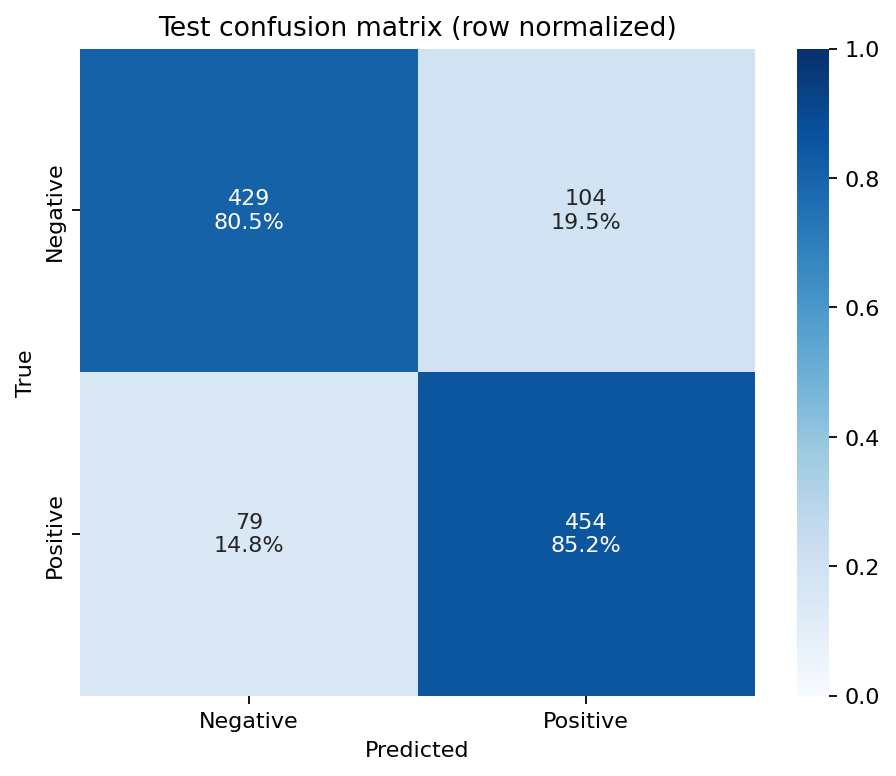

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095655Z_frozen_trial_d8d09116/confusion_matrix.png')]

In [7]:
display(session.table("model", "test_comparison.json"))
display(session.table("model", "test_runtime_metrics.json"))
session.show("model", ["confusion_matrix.png"])


### ROC/PR và calibration

Lượt lưu sẵn test loss 0.412560, ROC-AUC 0.8981, ECE 0.03795. ROC/PR là chẩn đoán sau khi khóa policy, không chọn threshold từ test. Bootstrap CI chỉ phản ánh lấy mẫu trên model/threshold cố định, không chứa biến thiên seed.

,roc_auc,average_precision,brier_score,confidence_ece,nll,threshold,selection_split,bootstrap_95_percentile_ci,bootstrap_repeats,ci_scope
0,0.898115,0.906652,0.128183,0.03795,0.412561,0.45,validation,"{'accuracy': [0.8058161350844277, 0.8508442776...",2000,"fixed model, fixed threshold, stratified test ..."


**roc_pr_curves.png**

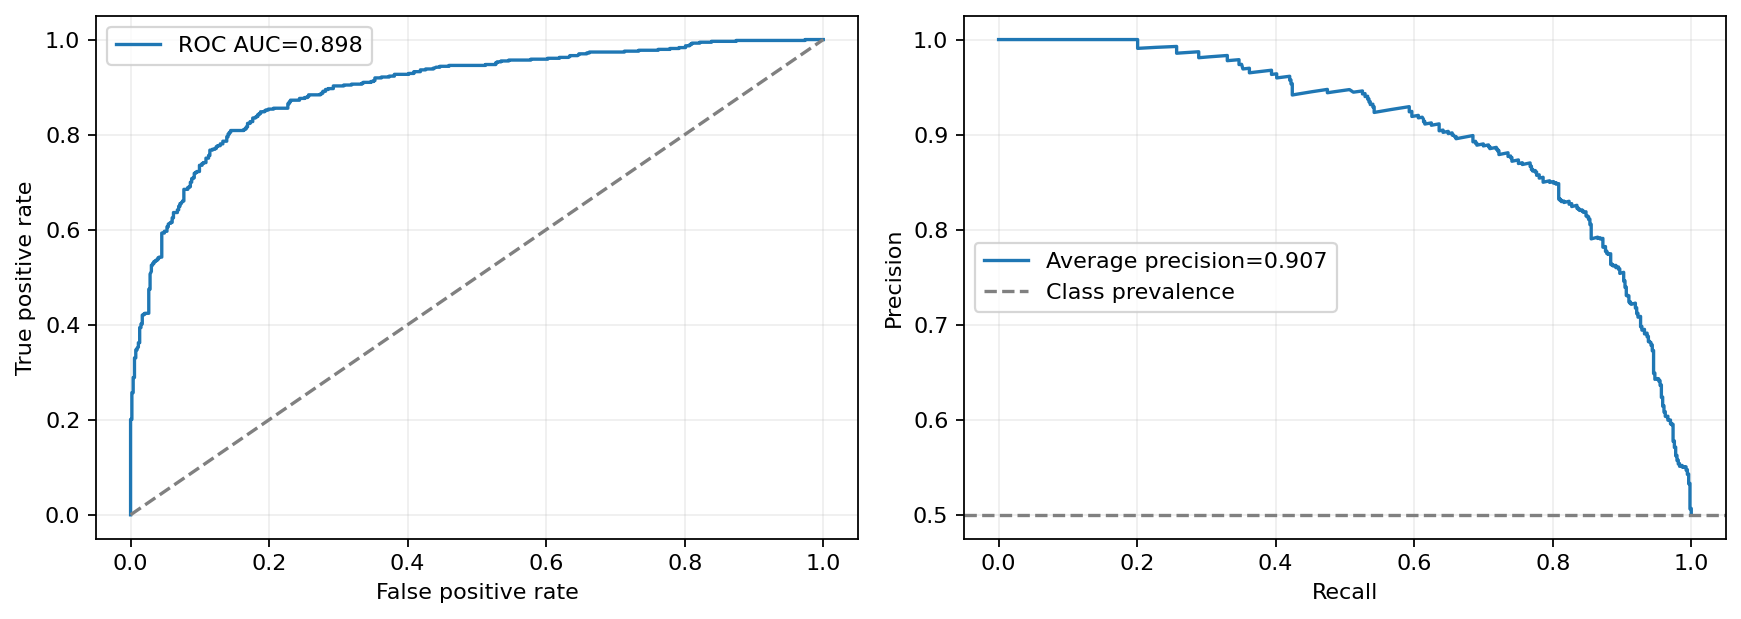

**calibration_confidence.png**

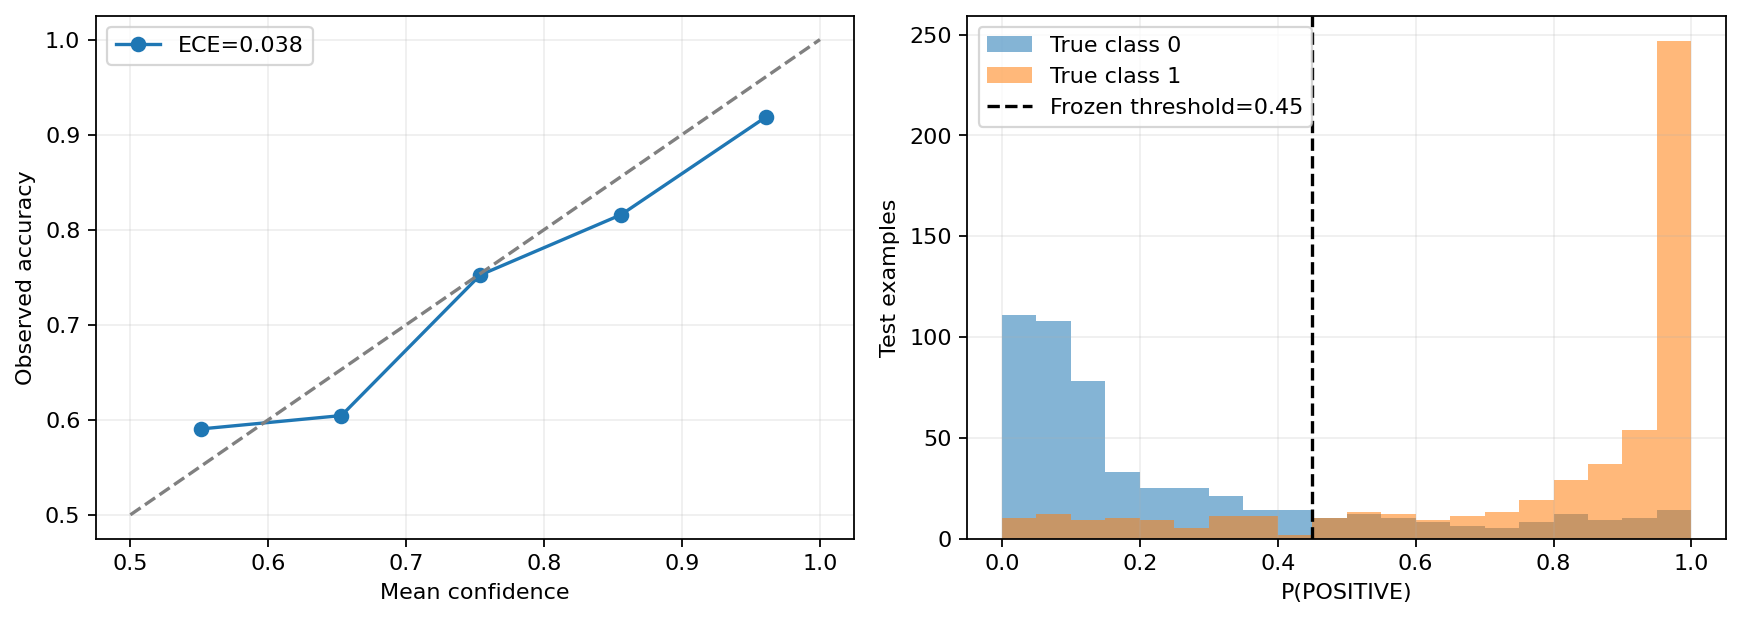

[PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095655Z_frozen_trial_d8d09116/roc_pr_curves.png'),
 PosixPath('/workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261027T095655Z_frozen_trial_d8d09116/calibration_confidence.png')]

In [8]:
display(session.table("model", "probability_diagnostics.json"))
session.show("model", ["roc_pr_curves.png", "calibration_confidence.png"])


## 7. Phân tích lỗi và so sánh lịch sử

MODE=view hiển thị review đã kiểm toán: frozen giảm overfitting/loss nhưng accuracy thấp hơn full fine-tuning 1.31 điểm phần trăm. Một seed và nhiều yếu tố đổi cùng lúc không cho phép quy nguyên nhân riêng cho freeze/dropout/LR. MODE=train không lấy ảnh review cũ gán cho run mới; đọc predictions và threshold_errors của run mới để phân tích.

,experiment,run_id,threshold,accuracy,precision,recall,binary_f1,macro_f1,TN,FP,FN,TP,test_loss,confidence_ece,brier_score
0,Unregularized 10 epoch,20261026T184219Z_study_94f2ba7b,0.50,0.833959,0.838403,0.827392,0.832861,0.833952,448,85,92,441,0.798076,0.146071,0.150674
1,Augmented full fine-tuning,20261027T083010Z_study_99bce559,0.65,0.841463,0.839552,0.844278,0.841908,0.841462,447,86,83,450,0.625951,0.130603,0.142356
2,Frozen 4 layers,20261027T095655Z_frozen_trial_d8d09116,0.45,0.828330,0.813620,0.851782,0.832264,0.828236,429,104,79,454,0.412560,0.037950,0.128183


**generalization_gaps.png**

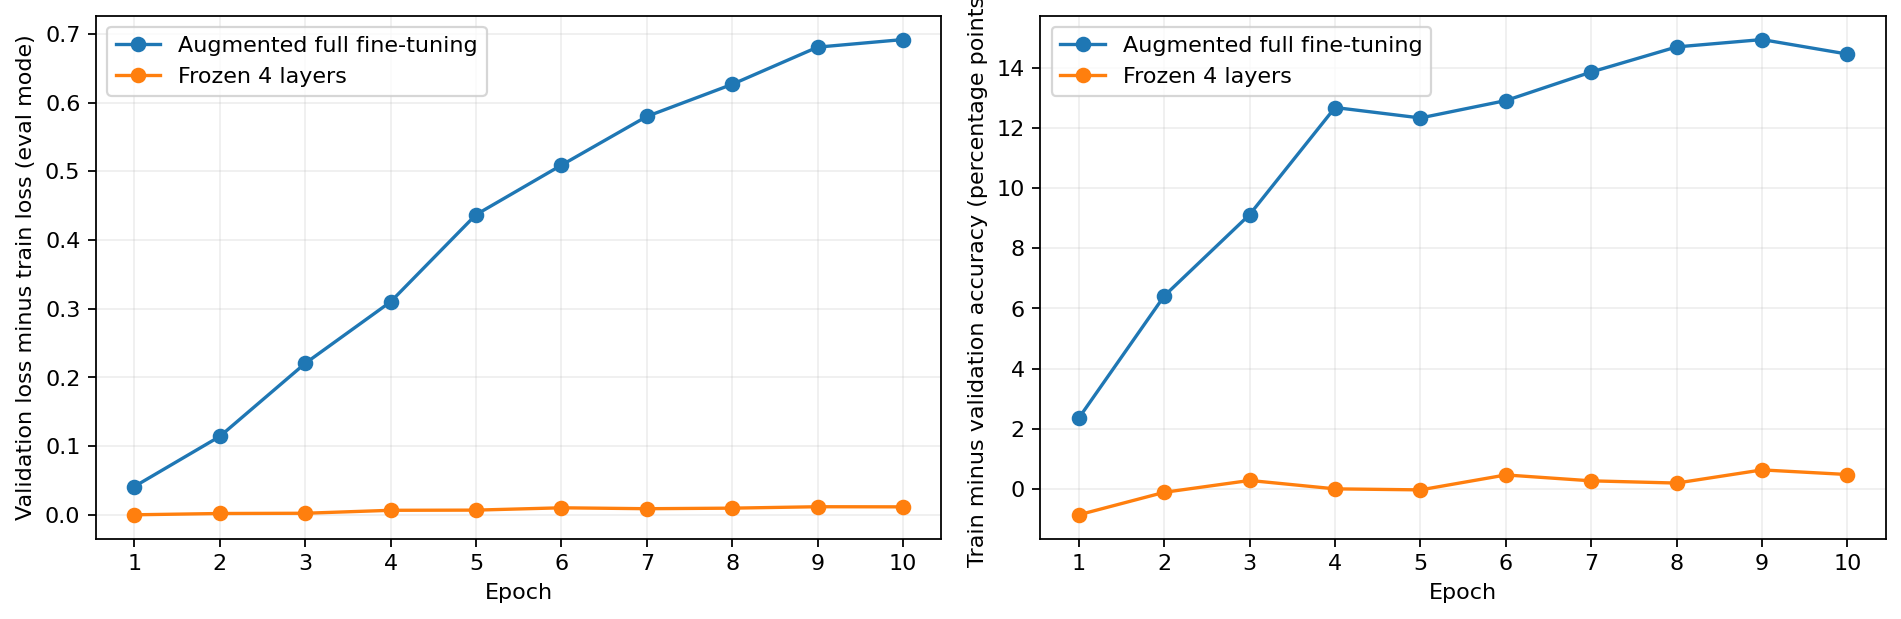

**experiment_comparison.png**

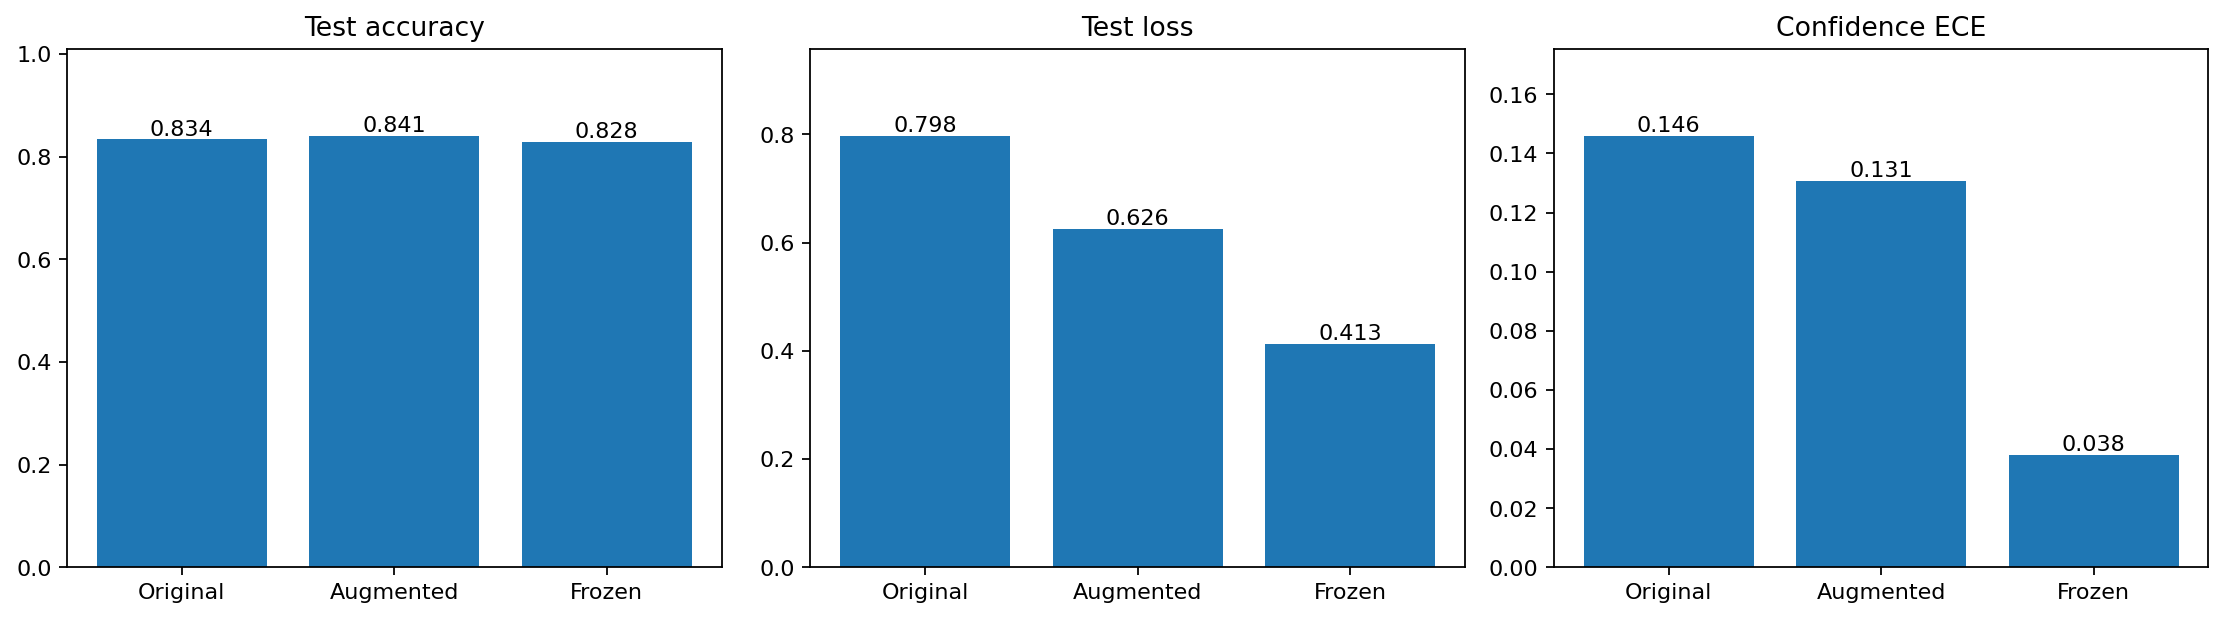

**per_class_metrics.png**

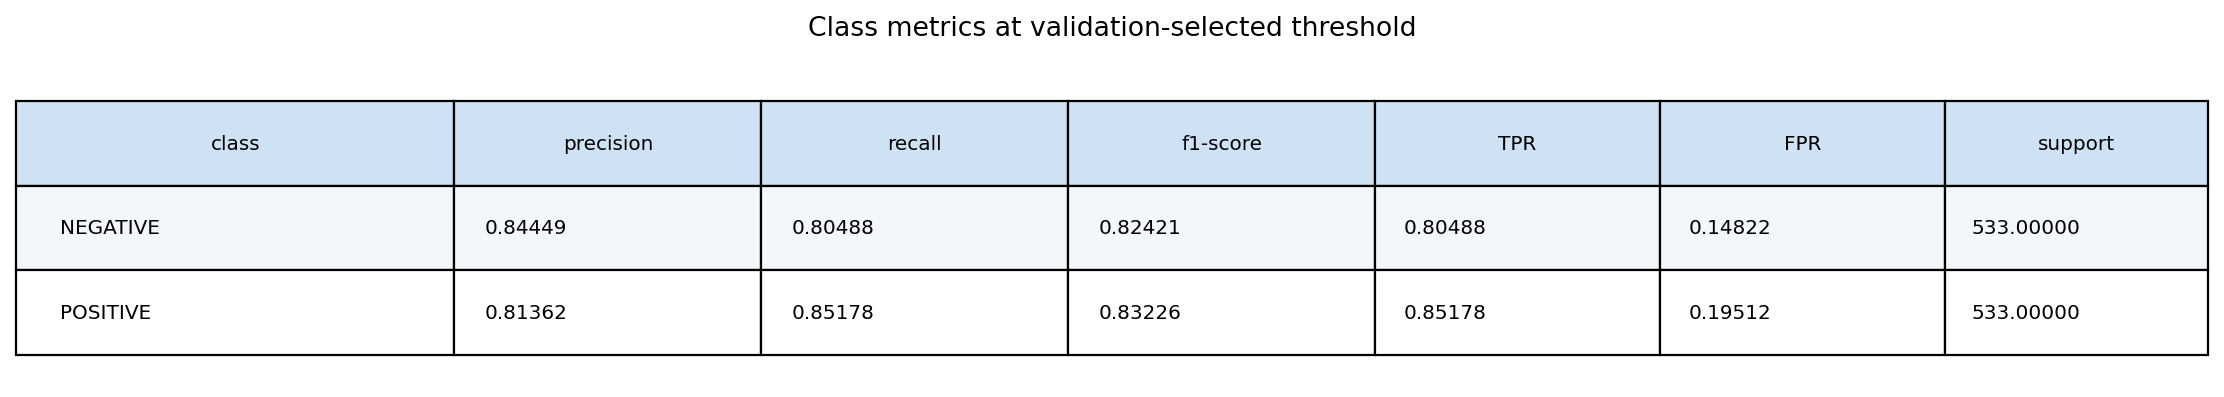

**sample_predictions.png**

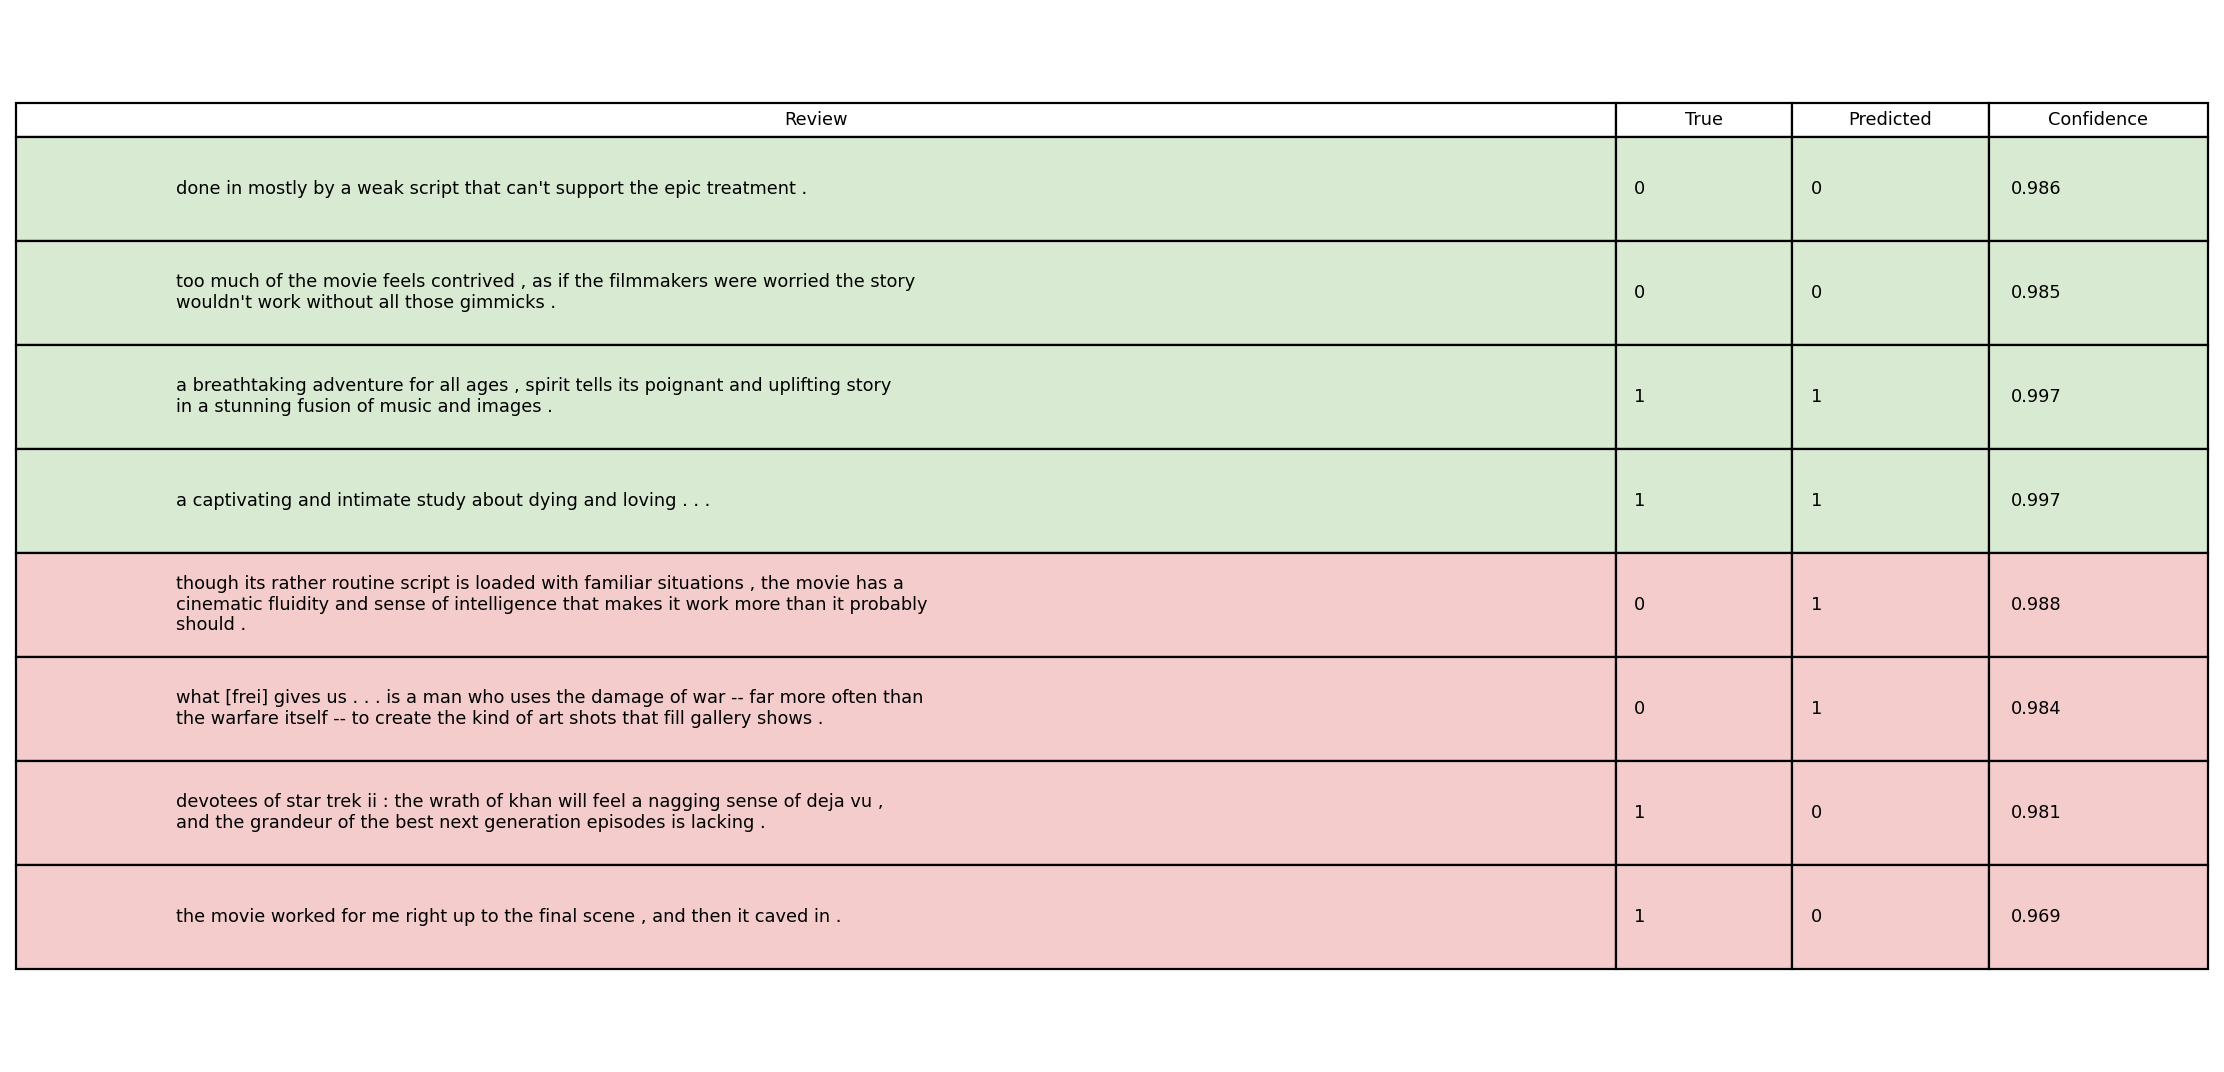

In [9]:
if MODE == "view":
    display(session.table("final_review", "comparison.json"))
    session.show("final_review", ["generalization_gaps.png", "experiment_comparison.png", "per_class_metrics.png", "sample_predictions.png"])
else:
    session.show("model", ["sample_predictions.png"])
    display(session.table("model", "threshold_errors.json").head(12))
    display(session.table("model", "test_predictions.json").head(8))


## 8. Save/load, artifact và tải ZIP

Artifact nằm trong outputs/ và ảnh đã hiện ngay trên notebook. MODE=view dùng outputs/published/index.md để lấy hình/bảng cho report, không train và không sinh lại kết quả. MODE=train tạo review ZIP và checkpoint ZIP riêng; giữ weights ngoài Git. Notebook tương tác có output cần tải qua File > Download Notebook, không nằm trong ZIP review của script.

In [10]:
reload_check = session.read(session.paths["model"]/"reload_check.json")
display({k:v for k,v in reload_check.items() if k != "predictions"})
session.export()


{'weights_exact_match': True, 'execution': 'CPU FP32, clean forward methods'}

Artifact report có sẵn: /workspace/Lab-DL-completion/labs/lab03/outputs/published/index.md


### Bảo vệ kết quả

Không khẳng định hoàn toàn không overfit. Hai đường gần nhau cũng có thể phản ánh khả năng thích nghi bị hạn chế. Explain freeze, LR head/encoder, criterion validation loss và threshold validation-only trước khi nêu accuracy. Source weights không có trong repo; audit offline dựa predictions/SHA256. Để inference checkpoint cũ, xem README về prepare_frozen_checkpoint.py.

[Walkthrough](../walkthrough_lab_03.md) giữ diễn tiến và câu hỏi bảo vệ; [artifact report](../outputs/published/index.md) chứa hình/bảng dùng trực tiếp.